# Módulo 3 KDD (Etapa 5): Minería de Datos — Detección de Anomalías (*Isolation Forest*), Balanceo *SMOTE* y Clasificación Supervisada

**Autor:** Roberto Alejandro Chagra Martínez (`208447128`)  
**Proyecto Integrador:** Detección Automatizada de Fraude con Tarjetas de Crédito (`credit_card_fraud_detection_2026.csv`)

---
## 1. Ejecución del Enfoque Híbrido (No Supervisado + Supervisado con *SMOTE*)
En este tercer módulo entrenamos `IsolationForest` para capturar anomalías geométricas, incorporamos `iso_anomaly_score` al vector de características (`45` variables seleccionadas), equilibramos la clase minoritaria en entrenamiento mediante `SMOTE` y entrenamos 5 algoritmos comparativos.

MÓDULO 1 (ETAPAS 1-3 KDD): SELECCIÓN, LIMPIEZA Y DIAGNÓSTICO DE OUTLIERS
[Etapa 1-2] Dataset original cargado: 100,000 filas x 43 columnas
  - Transacciones Legítimas (0):    97,945 (97.945%)
  - Transacciones Fraudulentas (1): 2,055 (2.055%) | Ratio 1:47.7
  - Pérdida económica acumulada:    $279,842.20 USD


g:\Mi unidad\Drive.alumno.udg.mx\5to\DATA_MINING_Y_KNOWLEDGE_DISCOVERY\proyecto_final\modulos_kdd\fase1_seleccion_y_limpieza.py:84: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=tipo_counts.values, y=tipo_counts.index, palette="OrRd_r", ax=axes[1], edgecolor="black")


[Etapa 2] Columnas descartadas por Data Leakage: ['fraud_type', 'fraud_amount_lost']
[Etapa 2] Dimensiones tras Selección: 100,000 filas x 35 columnas

[Etapa 3] Nulos detectados en 'browser': 41,709 -> Origen por canal: {'In-store': 35777, 'ATM': 5932}


[Etapa 3] Nulos tras imputación estructural: 0 | Duplicados: 0

[Etapa 3] Diagnóstico de Valores Atípicos (1.5 x IQR):
                Variable    Q1  Mediana      Q3     IQR  Lim_Sup  Outliers_Count  Outliers_%  Tasa_Fraude_Normal_%  Tasa_Fraude_Outlier_%  Lift_Riesgo
      transaction_amount 21.28    52.26  129.72  108.44   292.38            9959        9.96                  1.95                   3.02         1.55
          amount_last_1h  0.00     0.00  100.01  100.01   250.03           11150       11.15                  1.85                   3.71         2.01
   distance_from_home_km 20.60  1949.95 8482.35 8461.75 21174.97               0        0.00                  2.05                   0.00         0.00
distance_from_last_tx_km  5.20    13.30   31.90   26.70    71.95           15617       15.62                  1.85                   3.18         1.72
     amount_vs_avg_ratio  0.21     0.58    1.66    1.45     3.84           11309       11.31                  1.88            

[Etapa 4] Variables tras One-Hot Encoding: 91
[Etapa 4] X_train: (80000, 91) | X_test: (20000, 91)
[Etapa 4] Top 8 Variables Binarias por Estadístico Chi-Cuadrado:
                 Variable   Chi2_Stat       p_value
        high_risk_country 1625.744894  0.000000e+00
     merchant_country_USA  514.410212 6.961244e-114
   merchant_country_China  445.901142  5.625348e-99
 merchant_country_Romania  445.281433  7.673936e-99
international_transaction  411.662450  1.593146e-91
 merchant_country_Nigeria  400.035396  5.410399e-89
  merchant_country_Russia  352.642110  1.126650e-78
           is_new_account  323.110605  3.043367e-72

MÓDULO 3 (ETAPA 5 KDD): MINERÍA DE ANOMALÍAS (ISOLATION FOREST) Y CLASIFICACIÓN SMOTE


[Isolation Forest] Tasa Fraude Normales: 1.88% | Anómalas: 7.07% (Lift = 3.75x)


[SMOTE] X_train balanceado: Clase 0 = 78,356 | Clase 1 = 23,506


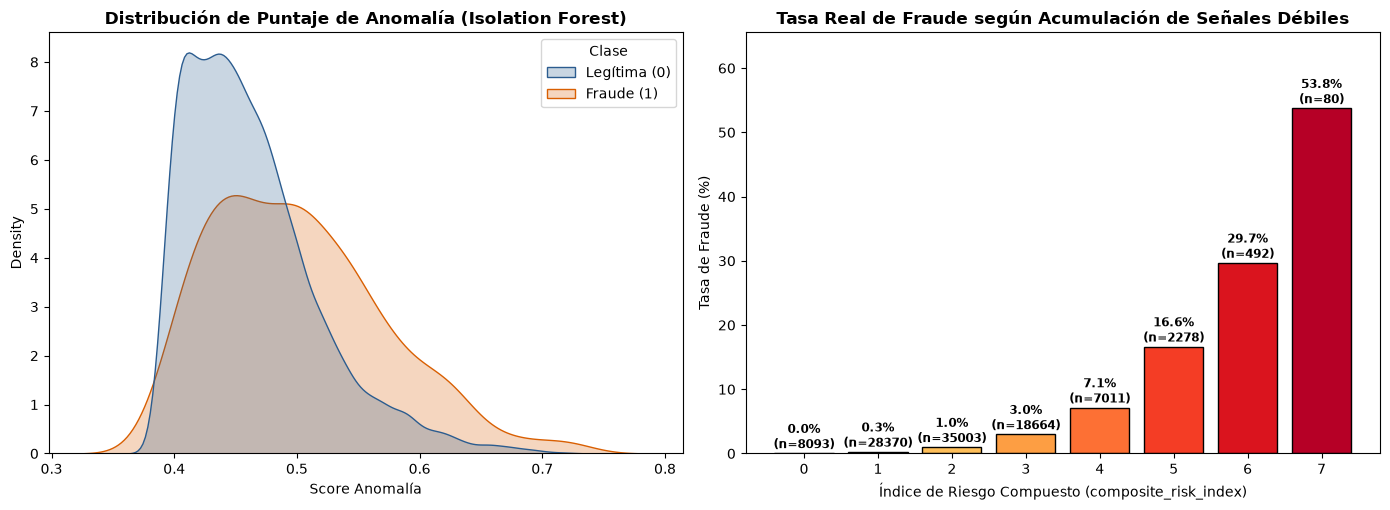

,Modelo,Umbral,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC,TP_Fraudes_Detectados,FN_Fraudes_Omitidos,FP_Falsas_Alarmas
0,1. Baseline Mayoritario (Dummy),0.50,0.9795,0.0000,0.0000,0.0000,0.5000,0.0205,0,411,0
1,2. Regresión Logística (SMOTE),0.35,0.8987,0.0903,0.4331,0.1495,0.8152,0.0964,178,233,1793
2,3. Árbol de Decisión (SMOTE),0.30,0.9367,0.1349,0.3844,0.1997,0.8103,0.1109,158,253,1013
3,4. Random Forest (SMOTE),0.50,0.8786,0.0895,0.5353,0.1534,0.8292,0.1039,220,191,2237
4,5. Gradient Boosting (SMOTE),0.15,0.9313,0.1288,0.4063,0.1956,0.8379,0.1369,167,244,1130


In [1]:
import sys
from pathlib import Path
from IPython.display import Image, display

project_root = Path.cwd().parent if (Path.cwd().parent / 'Datasets').exists() else Path.cwd()
modulos_dir = next(d for d in project_root.iterdir() if d.is_dir() and 'Python' in d.name)
if str(modulos_dir) not in sys.path:
    sys.path.insert(0, str(modulos_dir))
from fase1_seleccion_y_limpieza import (
    cargar_y_seleccionar_datos,
    limpiar_y_diagnosticar_outliers,
)
from fase2_transformacion_y_seleccion import transformar_y_particionar
from fase3_mineria_anomalias_y_clasificacion import ejecutar_mineria_datos

csv_path = project_root / 'Datasets' / 'credit_card_fraud_detection_2026.csv'
out_dir = project_root / 'Resultados'

_, df_sel = cargar_y_seleccionar_datos(csv_path, out_dir)
df_limpio, _ = limpiar_y_diagnosticar_outliers(df_sel, out_dir)
datos_etapa4 = transformar_y_particionar(df_limpio)
datos_etapa5 = ejecutar_mineria_datos(datos_etapa4, out_dir)

display(Image(filename=str(out_dir / '02_outliers_iqr_y_isolation_forest.png')))
display(datos_etapa5['df_res'])

### Análisis del Modelado Híbrido y del Balanceo con *SMOTE*
* **Detección No Supervisada (`IsolationForest`):** Las instancias marcadas como anómalas presentan una tasa real de fraude del **`7.07%`** frente al `1.88%` de las normales (**`3.75x` Lift**).
* **Impacto de *SMOTE* y Calibración de Umbral ($F_2\text{-Score}$):** Al equilibrar `X_train` (`78,356` legítimas vs. `23,506` fraudes sintéticos), **Random Forest (SMOTE)** detecta **`220` de los `411` fraudes (`Recall = 53.53%`, `ROC-AUC = 0.8292`)** y **Gradient Boosting (SMOTE)** alcanza el mayor **`ROC-AUC = 0.8379`** y **`PR-AUC = 0.1369`**.

### Q&A
* **¿Por qué se aplica `SMOTE` únicamente sobre `X_train` y nunca sobre `X_test`?** Porque `X_test` debe reflejar fielmente la distribución real del mundo productivo (`2.055%` de fraude); aplicar sobremuestreo en prueba distorsionaría las métricas de *Precision* y *PR-AUC*.

### Data Analysis Key Findings
* El puntaje `iso_anomaly_score` separa claramente la cola derecha de transacciones fraudulentas con un *Lift* de `3.75x`.
* Mientras el modelo *Baseline Mayoritario* obtiene `0.00%` de *Recall*, los modelos entrenados con *SMOTE* capturan entre el `38.44%` y el `53.53%` del fraude total en el conjunto de prueba oculto.
* *Gradient Boosting* lidera en discriminación global (`ROC-AUC = 0.8379`, `PR-AUC = 0.1369`) y *Random Forest* lidera en sensibilidad operativa (`220` fraudes capturados).

### Insights or Next Steps
* Evaluar visualmente las curvas ROC, Precision-Recall, matrices de confusión y extraer las reglas de decisión interpretables en el **Módulo 4 (`fase4_evaluacion_y_reglas_decision.py`)**.